### Load in Dependent Packages

In [1]:
import random
from collections import Counter
import pickle
import time

import numpy as np
from scipy.stats import norm,pearsonr
from sklearn.neighbors import KernelDensity
from sklearn.metrics import mean_squared_error, precision_recall_fscore_support, f1_score, precision_recall_curve, roc_curve, mean_absolute_error
from sklearn.preprocessing import StandardScaler

import torch as T
import torch.nn.functional as F
device = T.device("cpu")

import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.cm as cmx
from matplotlib.colors import ListedColormap, LinearSegmentedColormap

### Load in Data Sets

In [3]:
# PaperID -> [List(AuthorID), List(Lead AuthorID), List(Support AuthorID)]
f = open('GroundTruth', 'rb')
gt = pickle.load(f)
f.close()

<_io.BufferedReader name='GroundTruth'>

In [3]:

# PaperID -> List(AuthorID -> [career age, # previous publications, # previous citation, affiliation id, most frequent fields, list of (ref_id, previous cite frequency)])
f = open('Paper_Author_Feature_Dict', 'rb')
paper_author_feature_dict = pickle.load(f)
f.close()

# PaperID -> 27 Team Features:
# [0] team size; [1] field index; [2] #refs;
# [3] #author per affiliation; [4] percentage of authors in the dominant affiliation; [5] Gini(#author per affiliation);
# [6] #author per field; [7] percentage of authors at the dominant field; [8] Gini(#author per field);
# [9] Mean(career age); [10] Std(career age); [11] Gini(career age); 
# [12] Mean(#previous publications); [13] Std(#previous publications); [14] Gini(#previous publications);
# [15] Mean(#previous citations); [16] Std(#previous citations); [17] Gini(#previous citations);
# [18] Mean(#reference coverage); [19] Std(#reference coverage); [20] Gini(#reference coverage); 
# [21] Mean(#reference citation); [22] Std(#reference citation); [23] Gini(#reference citation); 
# [24] Mean(#reference surprise); [25] Std(#reference surprise); [26] Gini(#reference surprise); 
f = open('Paper_Team_Feature_Dict', 'rb')
paper_team_feature_dict = pickle.load(f)
f.close() 

In [4]:
def min_max(list_of_vals):
    return (np.min(list_of_vals), np.max(list_of_vals)-np.min(list_of_vals))

def gini_coef(list_of_values):
    sorted_list = sorted(list_of_values)
    height, area = 0, 0
    for value in sorted_list:
        height += value
        area += (height - value / 2.)
    fair_area = height * len(list_of_values) / 2.
    return (fair_area - area) / fair_area

### Classifying Author Roles

In [24]:
# Generate the role classification feature for each author

feature_array = []
id_array = []
role_array = []

for paperid in gt:
    
    author_id_list = gt[paperid][0]
    brain_ids = gt[paperid][1]
    muscle_ids = gt[paperid][2]
    
    team_avg_cite = min_max([paper_author_feature_dict[paperid][authorid][2] for authorid in author_id_list])
    team_avg_paper = min_max([paper_author_feature_dict[paperid][authorid][1] for authorid in author_id_list])
    team_avg_age = min_max([paper_author_feature_dict[paperid][authorid][0] for authorid in author_id_list])
    team_avg_refcover = min_max([len(paper_author_feature_dict[paperid][authorid][5]) for authorid in author_id_list])
    team_avg_refcite = min_max([sum([item[1] for item in paper_author_feature_dict[paperid][authorid][5]]) for authorid in author_id_list])
    
    for brain_author in brain_ids:
        cite = paper_author_feature_dict[paperid][brain_author][2]
        cite_team = (cite-team_avg_cite[0])/team_avg_cite[1] if team_avg_cite[1]!=0 else 0.5
        paper = paper_author_feature_dict[paperid][brain_author][1]
        paper_team = (paper-team_avg_paper[0])/team_avg_paper[1] if team_avg_paper[1]!=0 else 0.5
        age = paper_author_feature_dict[paperid][brain_author][0]
        age_team = (age-team_avg_age[0])/team_avg_age[1] if team_avg_age[1]!=0 else 0.5
        
        refcover = len(paper_author_feature_dict[paperid][brain_author][5])
        refcite = sum([item[1] for item in paper_author_feature_dict[paperid][brain_author][5]])
        refcover_team = (len(paper_author_feature_dict[paperid][brain_author][5])-team_avg_refcover[0])/team_avg_refcover[1] if team_avg_refcover[1]!=0 else 0.5
        refcite_team = (sum([item[1] for item in paper_author_feature_dict[paperid][brain_author][5]])-team_avg_refcite[0])/team_avg_refcite[1] if team_avg_refcite[1]!=0 else 0.5
        
        order_team = author_id_list.index(brain_author)/(len(author_id_list)-1)
        
        feature_array.append([cite, cite_team, paper, paper_team, age, age_team, refcover, refcite, refcover_team, refcite_team, order_team])
        id_array.append([paperid, brain_author])
        role_array.append([1])
        
    for muscle_author in muscle_ids:
        cite = paper_author_feature_dict[paperid][muscle_author][2]
        cite_team = (cite-team_avg_cite[0])/team_avg_cite[1] if team_avg_cite[1]!=0 else 0.5
        paper = paper_author_feature_dict[paperid][muscle_author][1]
        paper_team = (paper-team_avg_paper[0])/team_avg_paper[1] if team_avg_paper[1]!=0 else 0.5
        age = paper_author_feature_dict[paperid][muscle_author][0]
        age_team = (age-team_avg_age[0])/team_avg_age[1] if team_avg_age[1]!=0 else 0.5
        
        refcover = len(paper_author_feature_dict[paperid][muscle_author][5])
        refcite = sum([item[1] for item in paper_author_feature_dict[paperid][muscle_author][5]])
        refcover_team = (len(paper_author_feature_dict[paperid][muscle_author][5])-team_avg_refcover[0])/team_avg_refcover[1] if team_avg_refcover[1]!=0 else 0.5
        refcite_team = (sum([item[1] for item in paper_author_feature_dict[paperid][muscle_author][5]])-team_avg_refcite[0])/team_avg_refcite[1] if team_avg_refcite[1]!=0 else 0.5
        
        order_team = author_id_list.index(muscle_author)/(len(author_id_list)-1)
        
        feature_array.append([cite, cite_team, paper, paper_team, age, age_team, refcover, refcite, refcover_team, refcite_team, order_team])
        id_array.append([paperid, muscle_author])
        role_array.append([0])
        
print(len(feature_array),len(role_array))

571003 571003


In [25]:
# Partitioning Dataset

train_size = int(0.7*len(feature_array))
eval_size = int(0.1*len(feature_array))

train_ind = np.random.choice(len(feature_array), size=train_size, replace=False)
remain_ind = list(set(range(len(feature_array))) - set(train_ind))
eval_ind = np.random.choice(remain_ind, size=eval_size, replace=False)
test_ind = list(set(remain_ind) - set(eval_ind))

id_array = np.array(id_array)
feature_array = np.array(feature_array)
role_array = np.array(role_array)

scaler = StandardScaler()
feature_array = scaler.fit_transform(feature_array)

print(feature_array.shape[1], 'number of features.')

X_train, role_train, id_train = feature_array[train_ind, :], role_array[train_ind, :], id_array[train_ind, :]
X_eval, role_eval, id_eval = feature_array[eval_ind, :], role_array[eval_ind, :], id_array[eval_ind, :]
X_test, role_test, id_test = feature_array[test_ind, :], role_array[test_ind, :], id_array[test_ind, :]


print('Dataset Split:', len(train_ind), len(eval_ind), len(test_ind))

X_train_tensor, role_train_tensor = T.tensor(X_train, dtype=T.float32).to(device), T.tensor(role_train, dtype=T.float32).to(device)
X_eval_tensor, role_eval_tensor = T.tensor(X_eval, dtype=T.float32).to(device), T.tensor(role_eval, dtype=T.float32).to(device)
X_test_tensor, role_test_tensor = T.tensor(X_test, dtype=T.float32).to(device), T.tensor(role_test, dtype=T.float32).to(device)


11 number of features.
Dataset Split: 399702 57100 114201


In [26]:
# Defining Role Classification Neural Network

lr, hid1, hid2, hid3 = 0.001, 50, 100, 50

print("optimizer = Adam")
print("lrn_rate = %0.3f " % lr)
print("hid1 = %0.3f, hid2 =  %0.3f, hid2 =  %0.3f" % (hid1, hid2, hid3))

class Classify_Net(T.nn.Module):
    def __init__(self, hid1, hid2, hid3):
        super(Classify_Net, self).__init__()
        self.hid1 = T.nn.Linear(11, hid1)  
        self.hid2 = T.nn.Linear(hid1, hid2)
        self.hid3 = T.nn.Linear(hid2, hid3)
        self.oupt = T.nn.Linear(hid3, 1)
        self.sigmoid = T.nn.Sigmoid()
        self.relu = T.nn.ReLU()
        
        T.nn.init.xavier_uniform_(self.hid1.weight)
        T.nn.init.zeros_(self.hid1.bias)
        T.nn.init.xavier_uniform_(self.hid2.weight)
        T.nn.init.zeros_(self.hid2.bias)
        T.nn.init.xavier_uniform_(self.hid3.weight)
        T.nn.init.zeros_(self.hid3.bias)
        T.nn.init.xavier_uniform_(self.oupt.weight)
        T.nn.init.zeros_(self.oupt.bias)

    def forward(self, x):
        z = self.hid1(x)
        z = self.relu(z)
        
        z = self.hid2(z)
        z = self.relu(z)

        z = self.hid3(z)
        z = self.relu(z)
        
        z = self.oupt(z)
        z = self.sigmoid(z)
        return z

optimizer = Adam
lrn_rate = 0.001 
hid1 = 50.000, hid2 =  100.000, hid2 =  50.000


In [27]:
# Classifying Author Roles

# 1.2.2 Train Classifier Model 
def train_classifier(net, X_train_tensor, role_train_tensor, X_eval_tensor, role_eval_tensor, loss_func, lr, bat_size, max_epochs = 500):
    
    optimizer = T.optim.Adam(net.parameters(), lr=lr, weight_decay=0.005)
    
    for epoch in range(0, max_epochs):
        T.manual_seed(1+epoch)  # recovery reproducibility
        
        # Update Model
        net.train()  # set mode
        sample_ind = np.random.choice(len(role_train_tensor), size=bat_size, replace=False)
        sample_feat = X_train_tensor[sample_ind,:]
        sample_label = role_train_tensor[sample_ind,:]

        optimizer.zero_grad()
        sample_pred = net(sample_feat)
        with T.no_grad():
            sample_pred_nograd = net(sample_feat)

        loss = loss_func(sample_pred, sample_label)
        epoch_loss = loss.item()
        loss.backward()
        optimizer.step()
        
        # Evaluate Model
        net.eval()  # set mode
        with T.no_grad():
            oupt = net(X_eval_tensor)      # all computed prices
        y_pred = oupt.numpy()[:,0]
        y_true = role_eval_tensor.numpy()[:,0]
        temp = np.zeros(len(y_true))
        temp[y_pred>0.5] = 1
        y_pred = temp
        
        acc = sum(y_true == y_pred)/float(len(y_true))
        w_pre, w_rec, _, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')
        
        if epoch%50==0:
            print("Epoch=%3d, Loss=%0.4f:"%(epoch,epoch_loss), end='')
            print("\tEval=>Accuracy=%0.3f, Precision=%0.3f, Recall=%0.3f;" % (acc, w_pre, w_rec))    
    print("Done.")

seed=124
np.random.seed(seed)
T.manual_seed(seed)
random.seed(seed)

### Define Loss Function
bin_loss = T.nn.BCELoss()


### Initializing Neural Network
classify_net = Classify_Net(hid1, hid2, hid3).to(device)

### Starting Training Ranking Models
print('\nStart Training Classification Models')
train_classifier(classify_net, X_train_tensor, role_train_tensor, X_eval_tensor, role_eval_tensor, bin_loss, lr=0.0005, bat_size=10000, max_epochs = 1000)

# # ### Saving Final Models (state_dict approach)
fr = ".\\Models\\author_role_classifier.pth"
T.save(classify_net.state_dict(), fr)



Start Training Classification Models
Epoch=  0, Loss=0.7330:	Eval=>Accuracy=0.347, Precision=0.463, Recall=0.347;
Epoch= 50, Loss=0.5767:	Eval=>Accuracy=0.699, Precision=0.683, Recall=0.699;
Epoch=100, Loss=0.5393:	Eval=>Accuracy=0.734, Precision=0.725, Recall=0.734;
Epoch=150, Loss=0.5121:	Eval=>Accuracy=0.763, Precision=0.758, Recall=0.763;
Epoch=200, Loss=0.4952:	Eval=>Accuracy=0.780, Precision=0.777, Recall=0.780;
Epoch=250, Loss=0.4851:	Eval=>Accuracy=0.785, Precision=0.782, Recall=0.785;
Epoch=300, Loss=0.4743:	Eval=>Accuracy=0.788, Precision=0.784, Recall=0.788;
Epoch=350, Loss=0.4816:	Eval=>Accuracy=0.788, Precision=0.785, Recall=0.788;
Epoch=400, Loss=0.4809:	Eval=>Accuracy=0.789, Precision=0.786, Recall=0.789;
Epoch=450, Loss=0.4728:	Eval=>Accuracy=0.790, Precision=0.787, Recall=0.790;
Epoch=500, Loss=0.4800:	Eval=>Accuracy=0.790, Precision=0.787, Recall=0.790;
Epoch=550, Loss=0.4745:	Eval=>Accuracy=0.791, Precision=0.788, Recall=0.791;
Epoch=600, Loss=0.4702:	Eval=>Accuracy


Predicted Lead Likelihood


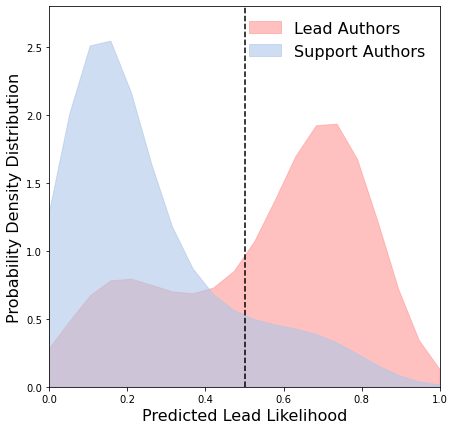

In [11]:
# Visualizing Classification Performance

def visual_role_classification(brain_prob, muscle_prob, xname, fig_para):
    xbegin = 0
    print('\n'+xname)

    cm = plt.get_cmap('tab20')
    cNorm  = colors.Normalize(vmin=0, vmax=19)
    scalarMap = cmx.ScalarMappable(norm=cNorm, cmap=cm)

    plt.figure(figsize=(7, 7),facecolor='white')
    
    xend, xstep = fig_para
    X_plot = np.linspace(0, xend, xstep)[:, np.newaxis]
    
    brain_kde = KernelDensity(kernel="gaussian", bandwidth=0.1).fit(np.array(brain_prob)[:, np.newaxis])
    brain_log_dens = brain_kde.score_samples(X_plot)
    plt.fill(np.concatenate(([0], X_plot[:, 0], [1])), np.concatenate(([0], np.exp(brain_log_dens), [0])), color = scalarMap.to_rgba(7), alpha = 0.6, label='Lead Authors')

    muscle_kde = KernelDensity(kernel="gaussian", bandwidth=0.1).fit(np.array(muscle_prob)[:, np.newaxis])
    muscle_log_dens = muscle_kde.score_samples(X_plot)
    plt.fill(np.concatenate(([0], X_plot[:, 0], [1])), np.concatenate(([0], np.exp(muscle_log_dens), [0])), color = scalarMap.to_rgba(1), alpha = 0.6, label='Support Authors')   
    
    plt.plot([0.5, 0.5], [0, 3.0], 'k--')
    
    
    plt.ylabel('Probability Density Distribution', fontsize=16)
    plt.xlabel(xname, fontsize=16)
    plt.ylim([0, 2.8])
    plt.xlim([0, 1])
    plt.legend(loc='upper right', fontsize=16,frameon=False)
    
    plt.show()
    

def to_labels(pos_probs, threshold):
    return (pos_probs >= threshold).astype('int')



classify_net.eval()  # set mode
with T.no_grad():
    oupt = classify_net(X_test_tensor)      # all computed prices
y_pred = oupt.numpy()[:,0]
y_true = role_test_tensor.numpy()[:,0]

brain_prob = y_pred[y_true==1]
muscle_prob = y_pred[y_true==0]

visual_role_classification(brain_prob, muscle_prob, 'Predicted Lead Likelihood', (1, 20))

### L-ratio Regression

In [13]:
# Splilt dataset by papers

paperid_norm_array = []
feature_norm_array = []
br_norm_array = []
nb_norm_array = []
size_norm_array = []


for paperid in paper_team_feature_dict:
    size = len(set(gt[paperid][0]))
    nb = len(gt[paperid][1])
    br = nb/size
    if br>0:
        paperid_norm_array.append(paperid)
        feature_norm_array.append(paper_team_feature_dict[paperid])
        br_norm_array.append(br)        
        nb_norm_array.append(nb)  
        size_norm_array.append(size)

nb_norm_array = np.array(nb_norm_array)
size_norm_array = np.array(size_norm_array)
paperid_norm_array = np.array(paperid_norm_array)
feature_norm_array = np.array(feature_norm_array)
br_norm_array = np.array(br_norm_array)


train_norm_size = int(0.7*len(feature_norm_array))
eval_norm_size = int(0.1*len(feature_norm_array))

### Generating Data index in Train, Evaluate and Test
train_norm_ind = np.random.choice(len(feature_norm_array), size=train_norm_size, replace=False)
remain_norm_ind = list(set(range(len(feature_norm_array))) - set(train_norm_ind))
eval_norm_ind = np.random.choice(remain_norm_ind, size=eval_norm_size, replace=False)
test_norm_ind = list(set(remain_norm_ind) - set(eval_norm_ind))

# # normallizing features
scaler = StandardScaler()
feature_norm_array = scaler.fit_transform(feature_norm_array)


# slicing dataset
X_norm_train, br_norm_train, nb_norm_train, size_norm_train = feature_norm_array[train_norm_ind, :], br_norm_array[train_norm_ind], nb_norm_array[train_norm_ind], size_norm_array[train_norm_ind]
X_norm_eval, br_norm_eval, nb_norm_eval, size_norm_eval = feature_norm_array[eval_norm_ind, :], br_norm_array[eval_norm_ind], nb_norm_array[eval_norm_ind], size_norm_array[eval_norm_ind]
X_norm_test, br_norm_test, nb_norm_test, size_norm_test = feature_norm_array[test_norm_ind, :], br_norm_array[test_norm_ind], nb_norm_array[test_norm_ind], size_norm_array[test_norm_ind]

print('\nDataset Split:', len(train_norm_ind), len(eval_norm_ind), len(test_norm_ind))


Dataset Split: 53657 7665 15331


In [18]:
# Define regression model

class Regress_Net(T.nn.Module):
    def __init__(self, hid1, hid2, hid3):
        super(Regress_Net, self).__init__()
        self.hid1 = T.nn.Linear(27, hid1) 
        self.hid2 = T.nn.Linear(hid1, hid2)
        self.hid3 = T.nn.Linear(hid2, hid3)
        self.oupt = T.nn.Linear(hid3, 1)
        self.sigmoid = T.nn.Sigmoid()
        self.relu = T.nn.ReLU()
        self.leaky_relu = T.nn.LeakyReLU()
        
        T.nn.init.xavier_uniform_(self.hid1.weight)
        T.nn.init.zeros_(self.hid1.bias)
        T.nn.init.xavier_uniform_(self.hid2.weight)
        T.nn.init.zeros_(self.hid2.bias)
        T.nn.init.xavier_uniform_(self.hid3.weight)
        T.nn.init.zeros_(self.hid3.bias)
        T.nn.init.xavier_uniform_(self.oupt.weight)
        T.nn.init.zeros_(self.oupt.bias)

    def forward(self, x):
        z = self.hid1(x)
        z = self.relu(z)
        
        z = self.hid2(z)
        z = self.relu(z)

        z = self.hid3(z)
        z = self.relu(z)
        
        z = self.oupt(z)  # no activation
        return z
    
lr, hid1, hid2, hid3 = 0.001, 50, 100, 50

print("optimizer = Adam")
print("lrn_rate = %0.3f " % lr)
print("hid1 = %0.3f, hid2 =  %0.3f, hid2 =  %0.3f" % (hid1, hid2, hid3))

optimizer = Adam
lrn_rate = 0.001 
hid1 = 50.000, hid2 =  100.000, hid2 =  50.000


In [22]:
# Train regression model

X_train_sel, X_eval_sel, X_test_sel, br_train_sel, br_eval_sel, br_test_sel, size_train_sel, size_eval_sel, size_test_sel = X_norm_train, X_norm_eval, X_norm_test, br_norm_train, br_norm_eval, br_norm_test, size_norm_train, size_norm_eval, size_norm_test

X_train_tensor, br_train_tensor = T.tensor(X_train_sel, dtype=T.float32).to(device), T.tensor(br_train_sel.reshape(-1,1), dtype=T.float32).to(device)
X_eval_tensor, br_eval_tensor = T.tensor(X_eval_sel, dtype=T.float32).to(device), T.tensor(br_eval_sel.reshape(-1,1), dtype=T.float32).to(device)
X_test_tensor, br_test_tensor = T.tensor(X_test_sel, dtype=T.float32).to(device), T.tensor(br_test_sel.reshape(-1,1), dtype=T.float32).to(device)
size_train_tensor = T.tensor(size_train_sel.reshape(-1,1), dtype=T.float32).to(device)
size_eval_tensor = T.tensor(size_eval_sel.reshape(-1,1), dtype=T.float32).to(device)
size_test_tensor = T.tensor(size_test_sel.reshape(-1,1), dtype=T.float32).to(device)


def train_regressor(net, X_train_tensor, br_train_tensor, X_eval_tensor, br_eval_tensor, loss_func, lr, bat_size, max_epochs = 500):
    
    optimizer = T.optim.Adam(net.parameters(), lr=lr, weight_decay=0.005)
    
    for epoch in range(0, max_epochs):
        T.manual_seed(1+epoch)  
        
        # Evaluate Model
        net.eval()  # set mode
        with T.no_grad():
            oupt = net(X_eval_tensor)   
        y_pred = oupt.numpy()[:,0]
        br_eval_temp = br_eval_tensor.numpy()[:,0]
        
        pr_eval = pearsonr(br_eval_temp, y_pred)
        mse_eval = mean_squared_error(br_eval_temp, y_pred)
        mae_eval = mean_absolute_error(br_eval_temp, y_pred)
        
        # Update Model
        net.train()  # set mode
        sample_ind = np.random.choice(len(br_train_tensor), size=bat_size, replace=False)
        sample_feat = X_train_tensor[sample_ind,:]
        sample_label = br_train_tensor[sample_ind,:]

        optimizer.zero_grad()
        sample_pred = net(sample_feat)
        with T.no_grad():
            sample_pred_nograd = net(sample_feat)

        loss = loss_func(sample_pred, sample_label)
        epoch_loss = loss.item()
        loss.backward()
        optimizer.step()
        
        y_pred = sample_pred_nograd.numpy()[:,0]
        br_train_temp = sample_label.numpy()[:, 0]
        pr_train = pearsonr(br_train_temp, y_pred)
        mse_train = mean_squared_error(br_train_temp, y_pred)
        mae_train = mean_absolute_error(br_train_temp, y_pred)
        
        if epoch%50==0:
            print("Epoch=%3d, Loss=%0.4f:"%(epoch,epoch_loss), end='')
            print("\tTrain=>Rho=%0.3f, MSE=%0.3f, MAE=%0.3f;" % (pr_train[0], mse_train, mae_train), end='')
            print("\tEval=>Rho=%0.3f, MSE=%0.3f, MAE=%0.3f;" % (pr_eval[0], mse_eval, mae_eval))    
    print("Done.")

seed=124
np.random.seed(seed)
T.manual_seed(seed)
random.seed(seed)

### Define Loss Function
mse_loss = T.nn.MSELoss()

### Initializing Neural Network
regress_net = Regress_Net(hid1, hid2, hid3).to(device)

### Starting Training Ranking Models
print('\nStart Training Regression Models')
train_regressor(regress_net, X_train_tensor, br_train_tensor, X_eval_tensor, br_eval_tensor, mse_loss, lr=0.0005, bat_size=10000, max_epochs = 1200)

# # ### Saving Final Models (state_dict approach)
fr = ".\\Models\\team_regression.pth"
T.save(regress_net.state_dict(), fr)



Start Training Regression Models
Epoch=  0, Loss=0.8465:	Train=>Rho=-0.125, MSE=0.847, MAE=0.823;	Eval=>Rho=-0.110, MSE=0.852, MAE=0.826;
Epoch= 50, Loss=0.0692:	Train=>Rho=0.483, MSE=0.069, MAE=0.203;	Eval=>Rho=0.496, MSE=0.067, MAE=0.201;
Epoch=100, Loss=0.0578:	Train=>Rho=0.554, MSE=0.058, MAE=0.186;	Eval=>Rho=0.560, MSE=0.057, MAE=0.187;
Epoch=150, Loss=0.0523:	Train=>Rho=0.592, MSE=0.052, MAE=0.178;	Eval=>Rho=0.592, MSE=0.053, MAE=0.180;
Epoch=200, Loss=0.0520:	Train=>Rho=0.605, MSE=0.052, MAE=0.177;	Eval=>Rho=0.613, MSE=0.051, MAE=0.176;
Epoch=250, Loss=0.0486:	Train=>Rho=0.621, MSE=0.049, MAE=0.172;	Eval=>Rho=0.626, MSE=0.049, MAE=0.174;
Epoch=300, Loss=0.0482:	Train=>Rho=0.638, MSE=0.048, MAE=0.172;	Eval=>Rho=0.636, MSE=0.048, MAE=0.172;
Epoch=350, Loss=0.0485:	Train=>Rho=0.630, MSE=0.048, MAE=0.172;	Eval=>Rho=0.643, MSE=0.047, MAE=0.171;
Epoch=400, Loss=0.0463:	Train=>Rho=0.638, MSE=0.046, MAE=0.168;	Eval=>Rho=0.647, MSE=0.047, MAE=0.170;
Epoch=450, Loss=0.0466:	Train=>Rho=0.

 - computing KDE in spherical coordinates


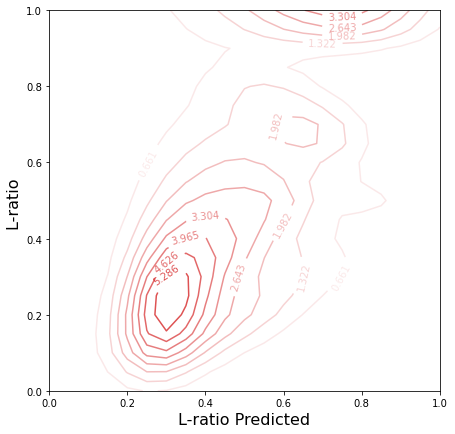

In [23]:

newred = np.array([[0.8392156862745098, 0.15294117647058825, 0.1568627450980392, ind/10] for ind in range(10)])
newcmp = ListedColormap(newred)

regress_net.eval()
with T.no_grad():
    oupt = regress_net(X_test_tensor)      # all computed prices

pred_br_test = oupt.numpy()[:,0]
br_test = br_test_tensor.numpy()[:,0]

################## filling the data sets
test_data = []
for ind in range(len(br_test)):
    test_data.append([br_test[ind], pred_br_test[ind]])
test_data = np.array(test_data)

# # Set up the data grid for the contour plot
X, Y = np.meshgrid(np.arange(0,1.05,0.05), np.arange(0,1.05,0.05))
xy = np.vstack([Y.ravel(), X.ravel()]).T

# Plot map of South America with distributions of each species
fig = plt.figure(figsize=(7, 7),facecolor='white')
ax = fig.add_subplot(111)

# construct a kernel density estimate of the distribution
print(" - computing KDE in spherical coordinates")
kde = KernelDensity(bandwidth=0.06, metric="haversine", kernel="gaussian", algorithm="ball_tree")
kde.fit(test_data)

# # evaluate only on the land: -9999 indicates ocean
Z = np.exp(kde.score_samples(xy))
Z = Z.reshape(X.shape)

# plot contours of the density
levels = np.linspace(0, Z.max(), 10)

handle = plt.contour(X, Y, Z, levels=levels, cmap=newcmp)
ax.clabel(handle, inline=True, fontsize=10)
plt.xlim([0,1])
plt.ylim([0,1])


plt.xlabel('L-ratio Predicted',fontsize=16)
plt.ylabel('L-ratio ',fontsize=16)

plt.show()
